# Excitonic optical absorption and second-harmonic generation
Let us see how the electron-hole attraction changes the optical response of an insulator, with
`h.get_excitonic_optical_conductivity()` and `h.get_excitonic_shg_susceptibility()`. Both solve the
Bethe-Salpeter equation at zero momentum in the Tamm-Dancoff approximation and sum over the
excitons: the absorption is a sum over the dipoles $R_{0n}$ of the excitons with the ground state,
and the second harmonic also needs the dipoles $R_{nm}$ between two excitons, which contain the
k-derivative of the exciton amplitudes. Without interaction, `kernel="none"`, the two functions
give back the results without excitons.
### Import the necessary libraries

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry
from pyqula.bsetk.interaction import density_interaction
from pyqula.bsetk.solve import BSE

### Second harmonic against the strength of the interaction
We take the gapped honeycomb lattice, gap $2t$, with a Coulomb tail $V(r)=V_0/\sqrt{r^2+0.25}$,
and increase $V_0$. The map shows $|\chi_{xxx}|$ as a function of the frequency and of $V_0$. The
dashed line is half the energy of the lowest exciton, and the dotted line is the exciton energy.

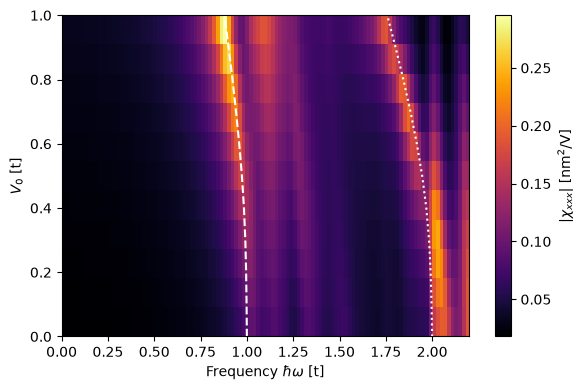

lowest exciton energies: [2.    1.997 1.992 1.983 1.969 1.946 1.917 1.883 1.845 1.803 1.758]


In [2]:
g = geometry.honeycomb_lattice()
h = g.get_hamiltonian(has_spin=False) # spinless, one spin species
h.add_sublattice_imbalance(1.0) # gap 2t at K and K'
V0s = np.linspace(0.,1.0,11) # strength of the Coulomb tail
ws = np.linspace(0.,2.2,111) # frequencies
chis,E1s = [],[]
for V0 in V0s:
    W = density_interaction(h,Vr=lambda r1,r2: V0/np.sqrt((r1-r2).dot(r1-r2)+0.25))
    if V0==0.: W[(0,0,0)] = 0.*W[(0,0,0)]
    (w,chi) = h.get_excitonic_shg_susceptibility(V=W,energies=ws,nk=21,delta=0.04,
                                                 components="xxx")
    chis.append(np.abs(chi))
    E1s.append(np.real(BSE(h,V=W,nk=21,tda=True).energies[0])) # lowest exciton

plt.figure(figsize=(6,4))
plt.imshow(np.array(chis),origin="lower",aspect="auto",cmap="inferno",
           extent=[ws[0],ws[-1],V0s[0],V0s[-1]])
plt.colorbar(label=r"$|\chi_{xxx}|$ [nm$^2$/V]")
plt.plot(np.array(E1s)/2.,V0s,c="white",ls="--") # 2w resonance
plt.plot(E1s,V0s,c="white",ls=":") # w resonance
plt.xlim(ws[0],ws[-1])
plt.xlabel(r"Frequency $\hbar\omega$ [t]") ; plt.ylabel("$V_0$ [t]")
plt.tight_layout()
plt.show()
print("lowest exciton energies:",np.round(E1s,3))

As $V_0$ grows, the lowest exciton moves below the gap and the second harmonic follows it: the
strongest feature is at half the exciton energy, where two photons create the exciton, and a
second one is at the exciton energy. The response below half the gap also grows, so the excitons
enhance the off-resonant second harmonic as well. At $V_0=0$ the exciton energy is the gap, and the
map is the response without excitons.

### Comparison with the literature
The sum over excitons is Eq. (1) of Ref. [1], with the position matrix element between excitons
evaluated as a k-derivative of the exciton written as a matrix in the orbitals, so no smooth
gauge of the Bloch states is needed. The equivalence with the other gauges is shown in Ref. [2].
The strong excitonic enhancement at half the energy of the bright exciton is the one found for
monolayer hBN in Ref. [1], where the enhancement at low frequency comes from the bright 1s exciton
together with 2p-like excitons that couple to it.

[1] J. Ruan, Y.-H. Chan, S. G. Louie, *Exciton enhanced nonlinear optical responses in monolayer
h-BN and MoS2: Insight from first-principles exciton-state coupling formalism and calculations*,
[arXiv:2310.09674](https://arxiv.org/abs/2310.09674)

[2] A. Taghizadeh, T. G. Pedersen, *Gauge invariance of excitonic linear and nonlinear optical
response*, Phys. Rev. B **97**, 205432 (2018),
[arXiv:1804.04869](https://arxiv.org/abs/1804.04869)